# Data Ingestion & Feature Engineering

## Robust Product Targeting Under Behavioral Distribution Shift

This notebook converts the raw X5 Retail Hero data into a customer-level modeling table for studying robust product targeting under changing customer behavior.

**Research question:** How reliable are product-targeting models when customer behavior changes, and can adaptive causal ML improve targeting under behavioral distribution shift?

The causal ordering is preserved throughout:

**pre-treatment purchase history → randomized treatment → post-treatment purchase outcome**

The notebook builds temporal behavioral features, customer-change diagnostics, product-category drift measures, and exploratory treatment-effect estimates before saving the final modeling table.

> **Execution note:** Code cells remain in their original dependency order. The markdown sections explain the analysis without changing the order in which variables are created.


# 1. Setup

Import the analysis libraries and define project paths. Raw inputs remain in `data/raw/`; reusable engineered data will be written to `data/processed/`.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_DIR = Path("../data/raw")

In [2]:
list(DATA_DIR.iterdir())

[PosixPath('../data/raw/purchases.csv'),
 PosixPath('../data/raw/products.csv'),
 PosixPath('../data/raw/.DS_Store'),
 PosixPath('../data/raw/clients.csv'),
 PosixPath('../data/raw/uplift_train.csv'),
 PosixPath('../data/raw/uplift_test.csv')]

# 2. Load and Inspect Core Data

Load customer metadata, product metadata, and the randomized uplift tables. The purchase-history file is much larger and is handled carefully later.

The audit establishes table dimensions, schemas, treatment balance, target prevalence, product taxonomy, and the time coverage of the purchase history.


In [3]:
clients = pd.read_csv(DATA_DIR / "clients.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
uplift_train = pd.read_csv(DATA_DIR / "uplift_train.csv")
uplift_test = pd.read_csv(DATA_DIR / "uplift_test.csv")

In [4]:
purchases_sample = pd.read_csv(
    DATA_DIR / "purchases.csv",
    nrows=100_000
)

In [5]:
purchases_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   client_id                100000 non-null  object 
 1   transaction_id           100000 non-null  object 
 2   transaction_datetime     100000 non-null  object 
 3   regular_points_received  100000 non-null  float64
 4   express_points_received  100000 non-null  float64
 5   regular_points_spent     100000 non-null  float64
 6   express_points_spent     100000 non-null  float64
 7   purchase_sum             100000 non-null  float64
 8   store_id                 100000 non-null  object 
 9   product_id               100000 non-null  object 
 10  product_quantity         100000 non-null  float64
 11  trn_sum_from_iss         100000 non-null  float64
 12  trn_sum_from_red         7231 non-null    float64
dtypes: float64(8), object(5)
memory usage: 9.9+ MB


In [6]:
purchases_sample.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_id,100000,880,00065f11c7,1015,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_id,100000,17292,543c8a7e4d,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_datetime,100000,17271,2019-03-01 16:46:12,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
regular_points_received,100000.0,NaN,NaN,NaN,8.35881,11.975958,0.0,1.4,5.5,11.1,197.0
express_points_received,100000.0,NaN,NaN,NaN,0.0495,1.637857,0.0,0.0,0.0,0.0,60.0
regular_points_spent,100000.0,NaN,NaN,NaN,-5.23641,31.218087,-690.0,0.0,0.0,0.0,0.0
express_points_spent,100000.0,NaN,NaN,NaN,-0.36838,3.454454,-60.0,0.0,0.0,0.0,0.0
purchase_sum,100000.0,NaN,NaN,NaN,800.741613,757.987183,0.0,295.0,569.0,1038.36,7586.0
store_id,100000,2245,94fce2166c,934,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,100000,13524,4009f09b04,4110,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
purchases_sample.head(20)

,client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,trn_sum_from_iss,trn_sum_from_red
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,9a80204f78,2.0,80.0,NaN
1,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,da89ebd374,1.0,65.0,NaN
2,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,0a95e1151d,1.0,24.0,NaN
3,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,4055b15e4a,2.0,50.0,NaN
4,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,a685f1916b,1.0,22.0,NaN
5,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,21db5dbe53,1.0,34.0,NaN
6,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,1e208d0b4c,1.0,24.0,NaN
7,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,15ccaa8685,1.0,51.0,NaN
8,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,45389bb5b0,1.0,23.0,NaN
9,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,cb4c804130,1.0,60.0,NaN


# 4. Reconstruct Transactions and Temporal Windows

`purchases.csv` is a product-line table: multiple rows can belong to the same basket and `purchase_sum` repeats across those lines. Therefore basket-level spending must be reconstructed at the unique customer–transaction level before aggregation.

The analysis uses four equal 28-day pre-treatment windows:

- **E1:** Nov 27–Dec 24, 2018
- **E2:** Dec 25, 2018–Jan 21, 2019
- **E3:** Jan 22–Feb 18, 2019
- **E4:** Feb 19–Mar 18, 2019

E1–E3 describe historical trajectory; E4 represents the most recent customer state before treatment.


In [8]:
date_min = None
date_max = None
total_rows = 0

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=["transaction_datetime"],
    chunksize=1_000_000
):
    dates = pd.to_datetime(chunk["transaction_datetime"])

    chunk_min = dates.min()
    chunk_max = dates.max()

    if date_min is None or chunk_min < date_min:
        date_min = chunk_min

    if date_max is None or chunk_max > date_max:
        date_max = chunk_max

    total_rows += len(chunk)

print("Total purchase rows:", f"{total_rows:,}")
print("Earliest purchase:", date_min)
print("Latest purchase:", date_max)
print("Observation window:", date_max - date_min)

Total purchase rows: 45,786,568
Earliest purchase: 2018-11-21 21:02:33
Latest purchase: 2019-03-18 23:40:03
Observation window: 117 days 02:37:30


In [9]:
daily_transactions = {}

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=["transaction_id", "transaction_datetime"],
    chunksize=1_000_000
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"]
    )

    # Multiple product rows belong to the same transaction,
    # so count each transaction only once within the chunk.
    transactions = chunk[
        ["transaction_id", "transaction_datetime"]
    ].drop_duplicates("transaction_id")

    dates = transactions["transaction_datetime"].dt.date
    counts = dates.value_counts()

    for date, count in counts.items():
        daily_transactions[date] = (
            daily_transactions.get(date, 0) + count
        )

daily_transactions = (
    pd.Series(daily_transactions)
    .sort_index()
)

daily_transactions.head()

2018-11-21       32
2018-11-22    61181
2018-11-23    65384
2018-11-24    60015
2018-11-25    55527
dtype: int64

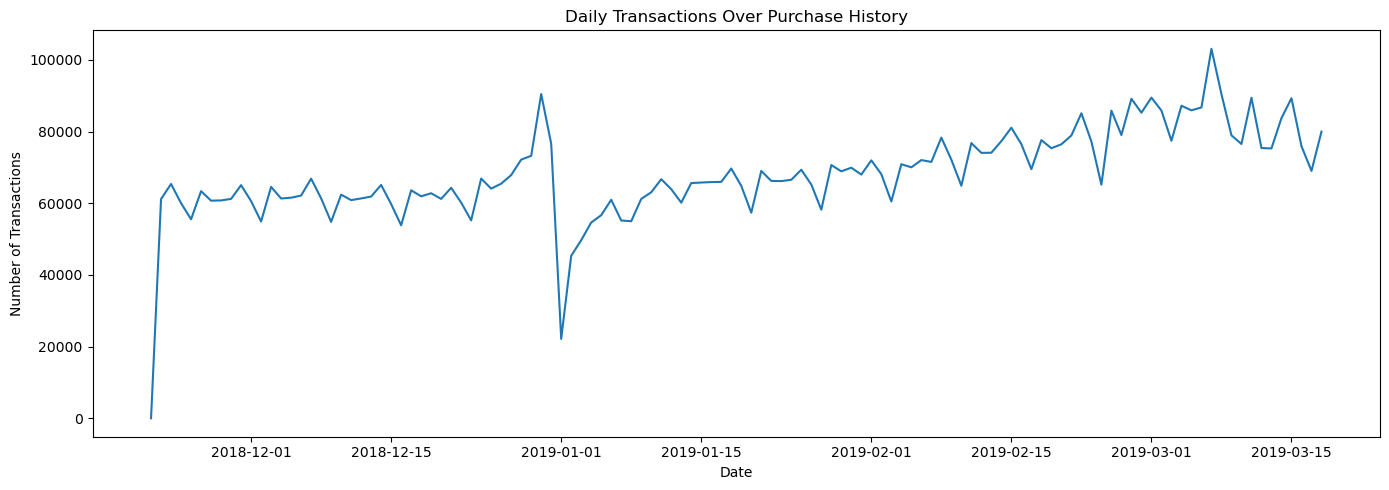

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

daily_transactions.plot()

plt.title("Daily Transactions Over Purchase History")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [11]:
customer_dates = {}

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=["client_id", "transaction_datetime"],
    chunksize=1_000_000
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"]
    )

    grouped = chunk.groupby("client_id")["transaction_datetime"].agg(
        ["min", "max"]
    )

    for client_id, row in grouped.iterrows():

        if client_id not in customer_dates:
            customer_dates[client_id] = [
                row["min"],
                row["max"]
            ]

        else:
            customer_dates[client_id][0] = min(
                customer_dates[client_id][0],
                row["min"]
            )

            customer_dates[client_id][1] = max(
                customer_dates[client_id][1],
                row["max"]
            )

In [12]:
customer_history = pd.DataFrame.from_dict(
    customer_dates,
    orient="index",
    columns=["first_purchase", "last_purchase"]
)

customer_history["history_days"] = (
    customer_history["last_purchase"]
    - customer_history["first_purchase"]
).dt.days

customer_history.head()

,first_purchase,last_purchase,history_days
000012768d,2018-12-01 07:12:45,2019-03-14 15:01:47,103
000036f903,2018-11-28 10:48:36,2019-03-17 10:29:37,108
000048b7a6,2018-12-15 10:33:11,2019-03-12 10:28:19,86
000073194a,2018-11-25 10:56:20,2019-03-16 09:41:21,110
00007c7133,2018-11-24 15:09:24,2019-03-04 16:23:30,100


In [13]:
customer_history["history_days"].describe(
    percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]
)

count    400162.000000
mean         90.855289
std          28.463147
min           0.000000
1%            0.000000
5%           20.000000
10%          46.000000
25%          84.000000
50%         102.000000
75%         110.000000
90%         114.000000
95%         115.000000
99%         116.000000
max         116.000000
Name: history_days, dtype: float64

In [14]:
print("Customers:", f"{len(customer_history):,}")

print(
    "\nFirst purchase date distribution:"
)

print(
    customer_history["first_purchase"]
    .dt.date
    .value_counts()
    .sort_index()
    .head(15)
)

print(
    "\nLast purchase date distribution:"
)

print(
    customer_history["last_purchase"]
    .dt.date
    .value_counts()
    .sort_index()
    .tail(15)
)

Customers: 400,162

First purchase date distribution:
first_purchase
2018-11-21       30
2018-11-22    54573
2018-11-23    43365
2018-11-24    30897
2018-11-25    22254
2018-11-26    20670
2018-11-27    16053
2018-11-28    13499
2018-11-29    11234
2018-11-30    10874
2018-12-01     9357
2018-12-02     7385
2018-12-03     7000
2018-12-04     6264
2018-12-05     5958
Name: count, dtype: int64

Last purchase date distribution:
last_purchase
2019-03-04     8362
2019-03-05     6181
2019-03-06     7210
2019-03-07    10207
2019-03-08    18176
2019-03-09    16891
2019-03-10    17785
2019-03-11    21585
2019-03-12    15321
2019-03-13    18030
2019-03-14    26690
2019-03-15    36842
2019-03-16    37302
2019-03-17    44340
2019-03-18    70273
Name: count, dtype: int64


In [15]:
uplift_train.head(10)

,client_id,treatment_flg,target
0,000012768d,0,1
1,000036f903,1,1
2,00010925a5,1,1
3,0001f552b0,1,1
4,00020e7b18,1,1
5,000220a0a7,0,1
6,00022fd34f,1,1
7,0002ce2217,0,1
8,00031cbbe6,0,1
9,00035a21d9,0,0


In [16]:
uplift_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200039 entries, 0 to 200038
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   client_id      200039 non-null  object
 1   treatment_flg  200039 non-null  int64 
 2   target         200039 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 4.6+ MB


In [17]:
print("Shape:", uplift_train.shape)

print("\nTreatment:")
print(uplift_train["treatment_flg"].value_counts())
print(
    uplift_train["treatment_flg"].value_counts(normalize=True)
)

print("\nTarget:")
print(uplift_train["target"].value_counts())
print(
    uplift_train["target"].value_counts(normalize=True)
)

Shape: (200039, 3)

Treatment:
treatment_flg
0    100058
1     99981
Name: count, dtype: int64
treatment_flg
0    0.500192
1    0.499808
Name: proportion, dtype: float64

Target:
target
1    124002
0     76037
Name: count, dtype: int64
target
1    0.619889
0    0.380111
Name: proportion, dtype: float64


In [18]:
pd.crosstab(
    uplift_train["treatment_flg"],
    uplift_train["target"],
    margins=True
)

target,0,1,All
treatment_flg,,,
0,39695,60363,100058
1,36342,63639,99981
All,76037,124002,200039


In [19]:
pd.crosstab(
    uplift_train["treatment_flg"],
    uplift_train["target"],
    normalize="index"
)

target,0,1
treatment_flg,,
0,0.396720,0.603280
1,0.363489,0.636511


In [20]:
clients.head(10)

,client_id,first_issue_date,first_redeem_date,age,gender
0,000012768d,2017-08-05 15:40:48,2018-01-04 19:30:07,45,U
1,000036f903,2017-04-10 13:54:23,2017-04-23 12:37:56,72,F
2,000048b7a6,2018-12-15 13:33:11,NaN,68,F
3,000073194a,2017-05-23 12:56:14,2017-11-24 11:18:01,60,F
4,00007c7133,2017-05-22 16:17:08,2018-12-31 17:17:33,67,U
5,00007f9014,2017-08-22 13:35:01,2019-02-15 19:19:18,45,F
6,0000a90cf7,2017-05-20 12:34:50,2017-07-08 12:48:22,45,U
7,0000b59cec,2017-06-09 10:04:20,2017-12-27 18:35:58,46,U
8,0000bb4e4e,2017-05-09 16:02:07,2017-08-25 17:03:01,36,M
9,0000bcec9c,2018-09-29 18:18:20,2019-09-29 11:52:58,34,U


In [21]:
clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400162 entries, 0 to 400161
Data columns (total 5 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   client_id          400162 non-null  object
 1   first_issue_date   400162 non-null  object
 2   first_redeem_date  364693 non-null  object
 3   age                400162 non-null  int64 
 4   gender             400162 non-null  object
dtypes: int64(1), object(4)
memory usage: 15.3+ MB


In [22]:
products.head(10)

,product_id,level_1,level_2,level_3,level_4,segment_id,brand_id,vendor_id,netto,is_own_trademark,is_alcohol
0,0003020d3c,c3d3a8e8c6,c2a3ea8d5e,b7cda0ec0c,6376f2a852,123.0,394a54a7c1,9eaff48661,0.400,0,0
1,0003870676,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f,105.0,acd3dd483f,10486c3cf0,0.680,0,0
2,0003ceaf69,c3d3a8e8c6,f2333c90fb,419bc5b424,f6148afbc0,271.0,f597581079,764e660dda,0.500,0,0
3,000701e093,ec62ce61e3,4202626fcb,88a515c084,48cf3d488f,172.0,54a90fe769,03c2d70bad,0.112,0,0
4,0007149564,e344ab2e71,52f13dac0c,d3cfe81323,6dc544533f,105.0,63417fe1f3,f329130198,0.600,0,0
5,0008bf7786,e344ab2e71,749c619457,5e89a8adcc,d453d4e1e8,165.0,0d6f137fb6,88f2ca925a,0.750,0,1
6,0009170c33,c3d3a8e8c6,ad2b2e17d2,ca69ed9de2,8bbeabc581,212.0,NaN,6a48b9976d,0.400,0,0
7,000b76558e,c3d3a8e8c6,d283080a93,f976a3c5f9,38c655d9b4,48.0,ea9e0181eb,8f55c680fa,0.450,0,0
8,00117bd32b,c3d3a8e8c6,ad2b2e17d2,eda7b2976b,1e7082b4bb,177.0,c34d31ceec,7e01a40bc1,0.250,0,0
9,0011ab9d97,e344ab2e71,ed2ad1797c,b25baa9dd5,fe255b600a,116.0,fce7934ead,95ea122ece,0.005,0,0


In [23]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43038 entries, 0 to 43037
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_id        43038 non-null  object 
 1   level_1           43035 non-null  object 
 2   level_2           43035 non-null  object 
 3   level_3           43035 non-null  object 
 4   level_4           43035 non-null  object 
 5   segment_id        41466 non-null  float64
 6   brand_id          37838 non-null  object 
 7   vendor_id         43004 non-null  object 
 8   netto             43035 non-null  float64
 9   is_own_trademark  43038 non-null  int64  
 10  is_alcohol        43038 non-null  int64  
dtypes: float64(2), int64(2), object(7)
memory usage: 3.6+ MB


In [24]:
products.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,43038,43038,0003020d3c,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level_1,43035,3,e344ab2e71,22183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level_2,43035,42,52f13dac0c,8891,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level_3,43035,201,ca69ed9de2,3737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
level_4,43035,790,420c3b3f0b,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment_id,41466.0,NaN,NaN,NaN,153.918222,82.271376,1.0,105.0,148.0,214.0,321.0
brand_id,37838,4296,0d6f137fb6,4344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vendor_id,43004,3193,43acd80c1a,1514,NaN,NaN,NaN,NaN,NaN,NaN,NaN
netto,43035.0,NaN,NaN,NaN,0.536966,8.274367,0.0,0.15,0.3,0.5,1150.0
is_own_trademark,43038.0,NaN,NaN,NaN,0.035178,0.184232,0.0,0.0,0.0,0.0,1.0


In [25]:
products.nunique()

product_id          43038
level_1                 3
level_2                42
level_3               201
level_4               790
segment_id            116
brand_id             4296
vendor_id            3193
netto                 780
is_own_trademark        2
is_alcohol              2
dtype: int64

In [26]:
CUTOFF_DATE = pd.Timestamp("2019-03-19")

In [27]:
CUTOFF_DATE = pd.Timestamp("2019-03-19")

periods = {
    "E1": (pd.Timestamp("2018-11-27"), pd.Timestamp("2018-12-25")),
    "E2": (pd.Timestamp("2018-12-25"), pd.Timestamp("2019-01-22")),
    "E3": (pd.Timestamp("2019-01-22"), pd.Timestamp("2019-02-19")),
    "E4": (pd.Timestamp("2019-02-19"), pd.Timestamp("2019-03-19")),
}

for name, (start, end) in periods.items():
    print(name, start.date(), "to", (end - pd.Timedelta(days=1)).date(),
          "=", (end - start).days, "days")

E1 2018-11-27 to 2018-12-24 = 28 days
E2 2018-12-25 to 2019-01-21 = 28 days
E3 2019-01-22 to 2019-02-18 = 28 days
E4 2019-02-19 to 2019-03-18 = 28 days


In [28]:
transaction_chunks = []

usecols = [
    "client_id",
    "transaction_id",
    "transaction_datetime",
    "purchase_sum",
    "product_quantity",
    "product_id"
]

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=usecols,
    chunksize=1_000_000
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"]
    )

    chunk = chunk[
        (chunk["transaction_datetime"] >= periods["E1"][0]) &
        (chunk["transaction_datetime"] < CUTOFF_DATE)
    ]

    tx = (
        chunk.groupby(
            ["client_id", "transaction_id"],
            as_index=False
        )
        .agg(
            transaction_datetime=("transaction_datetime", "first"),
            purchase_sum=("purchase_sum", "first"),
            quantity=("product_quantity", "sum"),
            unique_products=("product_id", "nunique")
        )
    )

    transaction_chunks.append(tx)

In [29]:
transactions = pd.concat(
    transaction_chunks,
    ignore_index=True
)

transactions.shape

(7739746, 6)

In [30]:
transactions = (
    transactions
    .groupby(
        ["client_id", "transaction_id"],
        as_index=False
    )
    .agg(
        transaction_datetime=("transaction_datetime", "first"),
        purchase_sum=("purchase_sum", "first"),
        quantity=("quantity", "sum"),
        unique_products=("unique_products", "sum")
    )
)

transactions.shape

(7739710, 6)

In [31]:
conditions = [
    (transactions["transaction_datetime"] >= periods["E1"][0]) &
    (transactions["transaction_datetime"] < periods["E1"][1]),

    (transactions["transaction_datetime"] >= periods["E2"][0]) &
    (transactions["transaction_datetime"] < periods["E2"][1]),

    (transactions["transaction_datetime"] >= periods["E3"][0]) &
    (transactions["transaction_datetime"] < periods["E3"][1]),

    (transactions["transaction_datetime"] >= periods["E4"][0]) &
    (transactions["transaction_datetime"] < periods["E4"][1])
]

transactions["period"] = np.select(
    conditions,
    ["E1", "E2", "E3", "E4"],
    default=None
)

transactions["period"].value_counts().sort_index()

period
E1    1717247
E2    1748780
E3    1976528
E4    2297155
Name: count, dtype: int64

In [32]:
print("Transaction table shape:", transactions.shape)

print("\nTransactions per period:")
print(transactions["period"].value_counts().sort_index())

print("\nTransaction-level summary:")
print(
    transactions[
        ["purchase_sum", "quantity", "unique_products"]
    ].describe()
)

Transaction table shape: (7739710, 7)

Transactions per period:
period
E1    1717247
E2    1748780
E3    1976528
E4    2297155
Name: count, dtype: int64

Transaction-level summary:
       purchase_sum      quantity  unique_products
count  7.739710e+06  7.739710e+06     7.739710e+06
mean   4.289205e+02  7.097406e+00     5.691530e+00
std    4.909320e+02  1.126150e+01     5.012078e+00
min    0.000000e+00  0.000000e+00     1.000000e+00
25%    1.402900e+02  3.000000e+00     2.000000e+00
50%    2.820000e+02  5.000000e+00     4.000000e+00
75%    5.331700e+02  9.000000e+00     7.000000e+00
max    3.514904e+04  1.845700e+04     1.160000e+02


# 5. Customer-Period Behavioral Features

Aggregate reconstructed baskets to customer-period features such as transaction frequency, total spending, basket size, quantity, and product diversity.

The complete customer × period grid is retained. A zero-activity period is meaningful customer behavior rather than ordinary missing data.

A later audit shows that the competition population is effectively conditioned on recent E4 activity. For that reason, raw E4−E1 differences should not automatically be interpreted as genuine customer drift.


In [33]:
customer_period = (
    transactions
    .groupby(
        ["client_id", "period"],
        as_index=False
    )
    .agg(
        transactions=("transaction_id", "nunique"),
        total_spend=("purchase_sum", "sum"),
        avg_basket_spend=("purchase_sum", "mean"),
        total_quantity=("quantity", "sum"),
        avg_quantity=("quantity", "mean"),
        avg_unique_products=("unique_products", "mean")
    )
)

customer_period.head(10)

,client_id,period,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products
0,000012768d,E1,2,1581.0,790.50,35.0,17.50,15.00
1,000012768d,E4,2,1222.0,611.00,19.0,9.50,11.00
2,000036f903,E1,10,2947.0,294.70,47.0,4.70,4.80
3,000036f903,E2,4,1492.0,373.00,27.0,6.75,6.00
4,000036f903,E3,10,2582.0,258.20,45.0,4.50,4.60
5,000036f903,E4,8,2784.0,348.00,50.0,6.25,5.50
6,000048b7a6,E1,1,445.0,445.00,11.0,11.00,9.00
7,000048b7a6,E2,2,758.0,379.00,32.0,16.00,8.00
8,000048b7a6,E3,4,2227.0,556.75,45.0,11.25,7.25
9,000048b7a6,E4,1,342.0,342.00,3.0,3.00,2.00


In [34]:
client_period_grid = pd.MultiIndex.from_product(
    [
        clients["client_id"].unique(),
        ["E1", "E2", "E3", "E4"]
    ],
    names=["client_id", "period"]
).to_frame(index=False)

customer_period = client_period_grid.merge(
    customer_period,
    on=["client_id", "period"],
    how="left"
)

In [35]:
behavior_cols = [
    "transactions",
    "total_spend",
    "avg_basket_spend",
    "total_quantity",
    "avg_quantity",
    "avg_unique_products"
]

customer_period[behavior_cols] = (
    customer_period[behavior_cols].fillna(0)
)

In [36]:
print("Shape:", customer_period.shape)

print("\nTransactions by period:")
print(
    customer_period.groupby("period")["transactions"]
    .agg(["mean", "median", "std"])
)

print("\nCustomers with zero transactions:")
print(
    customer_period
    .assign(zero=lambda x: x["transactions"] == 0)
    .groupby("period")["zero"]
    .agg(["sum", "mean"])
)

Shape: (1600648, 8)

Transactions by period:
            mean  median       std
period                            
E1      4.291379     3.0  4.863877
E2      4.370180     3.0  4.669260
E3      4.939320     4.0  5.116962
E4      5.740563     4.0  5.244726

Customers with zero transactions:
          sum      mean
period                 
E1      85255  0.213051
E2      72791  0.181904
E3      55627  0.139011
E4          0  0.000000


In [37]:
print(
    customer_period[
        [
            "transactions",
            "total_spend",
            "avg_basket_spend",
            "total_quantity"
        ]
    ].describe(
        percentiles=[.01, .05, .25, .5, .75, .95, .99]
    )
)

       transactions   total_spend  avg_basket_spend  total_quantity
count  1.600648e+06  1.600648e+06      1.600648e+06    1.600648e+06
mean   4.835360e+00  2.073985e+03      4.306688e+02    3.431851e+01
std    5.012286e+00  2.590541e+03      4.477316e+02    4.478742e+01
min    0.000000e+00  0.000000e+00      0.000000e+00    0.000000e+00
1%     0.000000e+00  0.000000e+00      0.000000e+00    0.000000e+00
5%     0.000000e+00  0.000000e+00      0.000000e+00    0.000000e+00
25%    1.000000e+00  4.600000e+02      1.664650e+02    8.000000e+00
50%    3.000000e+00  1.348950e+03      3.231871e+02    2.300000e+01
75%    7.000000e+00  2.785253e+03      5.595700e+02    4.700000e+01
95%    1.400000e+01  6.624000e+03      1.238583e+03    1.080000e+02
99%    2.300000e+01  1.174370e+04      2.115724e+03    1.810000e+02
max    2.780000e+02  2.448420e+05      3.514904e+04    1.849500e+04


In [38]:
last_tx = (
    transactions
    .groupby("client_id")["transaction_datetime"]
    .max()
)

days_before_cutoff = (
    CUTOFF_DATE - last_tx
).dt.days

days_before_cutoff.describe(
    percentiles=[.01, .05, .10, .25, .50, .75, .90, .95, .99]
)

count    400162.000000
mean          5.839233
std           5.672085
min           0.000000
1%            0.000000
5%            0.000000
10%           0.000000
25%           1.000000
50%           4.000000
75%           9.000000
90%          15.000000
95%          18.000000
99%          21.000000
max          22.000000
Name: transaction_datetime, dtype: float64

In [39]:
days_before_cutoff.value_counts().sort_index().head(30)

transaction_datetime
0     70273
1     44340
2     37302
3     36842
4     26690
5     18030
6     15321
7     21585
8     17785
9     16891
10    18176
11    10207
12     7210
13     6181
14     8362
15     7327
16     8037
17     7288
18     6339
19     6049
20     4933
21     4993
22        1
Name: count, dtype: int64

In [40]:
train_ids = set(uplift_train["client_id"])

train_period = customer_period[
    customer_period["client_id"].isin(train_ids)
].copy()

print(
    train_period.groupby("period")["transactions"]
    .agg(["mean", "median", "std"])
)

print("\nZero transaction rate:")
print(
    train_period
    .assign(zero=lambda x: x["transactions"] == 0)
    .groupby("period")["zero"]
    .mean()
)

            mean  median       std
period                            
E1      4.296892     3.0  4.867654
E2      4.369503     3.0  4.668881
E3      4.944086     4.0  5.123533
E4      5.745890     4.0  5.223274

Zero transaction rate:
period
E1    0.211689
E2    0.182199
E3    0.138828
E4    0.000000
Name: zero, dtype: float64


In [41]:
print("All clients in purchases:",
      customer_period["client_id"].nunique())

print("Train clients:",
      uplift_train["client_id"].nunique())

print("Test clients:",
      uplift_test["client_id"].nunique())

print("Train + test:",
      uplift_train["client_id"].nunique()
      + uplift_test["client_id"].nunique())

All clients in purchases: 400162
Train clients: 200039
Test clients: 200123
Train + test: 400162


In [42]:
customer_features = customer_period.pivot(
    index="client_id",
    columns="period",
    values=[
        "transactions",
        "total_spend",
        "avg_basket_spend",
        "total_quantity",
        "avg_quantity",
        "avg_unique_products"
    ]
)

customer_features.columns = [
    f"{feature}_{period}"
    for feature, period in customer_features.columns
]

customer_features = customer_features.reset_index()

customer_features.head()

,client_id,transactions_E1,transactions_E2,transactions_E3,transactions_E4,total_spend_E1,total_spend_E2,total_spend_E3,total_spend_E4,avg_basket_spend_E1,avg_basket_spend_E2,avg_basket_spend_E3,avg_basket_spend_E4,total_quantity_E1,total_quantity_E2,total_quantity_E3,total_quantity_E4,avg_quantity_E1,avg_quantity_E2,avg_quantity_E3,avg_quantity_E4,avg_unique_products_E1,avg_unique_products_E2,avg_unique_products_E3,avg_unique_products_E4
0,000012768d,2.0,0.0,0.0,2.0,1581.00,0.00,0.00,1222.0,790.500000,0.0000,0.000000,611.00,35.0,0.0,0.0,19.0,17.500000,0.00,0.000000,9.500000,15.000000,0.00,0.000000,11.000000
1,000036f903,10.0,4.0,10.0,8.0,2947.00,1492.00,2582.00,2784.0,294.700000,373.0000,258.200000,348.00,47.0,27.0,45.0,50.0,4.700000,6.75,4.500000,6.250000,4.800000,6.00,4.600000,5.500000
2,000048b7a6,1.0,2.0,4.0,1.0,445.00,758.00,2227.00,342.0,445.000000,379.0000,556.750000,342.00,11.0,32.0,45.0,3.0,11.000000,16.00,11.250000,3.000000,9.000000,8.00,7.250000,2.000000
3,000073194a,3.0,4.0,3.0,6.0,745.16,3203.87,1780.07,3393.3,248.386667,800.9675,593.356667,565.55,13.0,53.0,23.0,34.0,4.333333,13.25,7.666667,5.666667,2.333333,7.75,6.333333,3.833333
4,00007c7133,3.0,4.0,2.0,1.0,1560.00,3040.00,1420.84,380.0,520.000000,760.0000,710.420000,380.00,14.0,36.0,18.0,6.0,4.666667,9.00,9.000000,6.000000,4.666667,9.00,8.500000,8.000000


In [43]:
print(customer_features.shape)
print(customer_features.columns.tolist())

(400162, 25)
['client_id', 'transactions_E1', 'transactions_E2', 'transactions_E3', 'transactions_E4', 'total_spend_E1', 'total_spend_E2', 'total_spend_E3', 'total_spend_E4', 'avg_basket_spend_E1', 'avg_basket_spend_E2', 'avg_basket_spend_E3', 'avg_basket_spend_E4', 'total_quantity_E1', 'total_quantity_E2', 'total_quantity_E3', 'total_quantity_E4', 'avg_quantity_E1', 'avg_quantity_E2', 'avg_quantity_E3', 'avg_quantity_E4', 'avg_unique_products_E1', 'avg_unique_products_E2', 'avg_unique_products_E3', 'avg_unique_products_E4']


In [44]:
model_data = uplift_train.merge(
    customer_features,
    on="client_id",
    how="left"
)

print(model_data.shape)
print(model_data.isna().sum().sort_values(ascending=False).head(10))

(200039, 27)
client_id                 0
avg_basket_spend_E4       0
avg_unique_products_E3    0
avg_unique_products_E2    0
avg_unique_products_E1    0
avg_quantity_E4           0
avg_quantity_E3           0
avg_quantity_E2           0
avg_quantity_E1           0
total_quantity_E4         0
dtype: int64


# 6. Historical Trends, Recent Deviations, and Behavioral Instability

Separate two ideas:

- **Historical trend:** whether behavior was already moving across E1–E3.
- **Recent deviation:** how far E4 lies from the customer's historical baseline.

Because the overall population changes over time, recent deviations are standardized relative to the training population before being combined into a behavioral-instability diagnostic.

This score is useful for stratification, but it is not treated as a perfect latent measure because transaction frequency, spending, and quantity are correlated.


In [45]:
trend_features = [
    "transactions",
    "total_spend",
    "avg_basket_spend",
    "total_quantity"
]

In [46]:
for feature in trend_features:
    model_data[f"{feature}_trend"] = (
        model_data[f"{feature}_E3"]
        - model_data[f"{feature}_E1"]
    ) / 2

In [47]:
for feature in trend_features:

    historical_cols = [
        f"{feature}_E1",
        f"{feature}_E2",
        f"{feature}_E3"
    ]

    model_data[f"{feature}_historical_mean"] = (
        model_data[historical_cols].mean(axis=1)
    )

    model_data[f"{feature}_recent_deviation"] = (
        model_data[f"{feature}_E4"]
        - model_data[f"{feature}_historical_mean"]
    )

In [48]:
cols = [
    "client_id",
    "transactions_E1",
    "transactions_E2",
    "transactions_E3",
    "transactions_E4",
    "transactions_trend",
    "transactions_historical_mean",
    "transactions_recent_deviation"
]

model_data[cols].head(15)

,client_id,transactions_E1,transactions_E2,transactions_E3,transactions_E4,transactions_trend,transactions_historical_mean,transactions_recent_deviation
0,000012768d,2.0,0.0,0.0,2.0,-1.0,0.666667,1.333333
1,000036f903,10.0,4.0,10.0,8.0,0.0,8.000000,0.000000
2,00010925a5,5.0,1.0,4.0,7.0,-0.5,3.333333,3.666667
3,0001f552b0,2.0,2.0,4.0,6.0,1.0,2.666667,3.333333
4,00020e7b18,5.0,1.0,6.0,5.0,0.5,4.000000,1.000000
5,000220a0a7,2.0,2.0,3.0,8.0,0.5,2.333333,5.666667
6,00022fd34f,8.0,7.0,6.0,10.0,-1.0,7.000000,3.000000
7,0002ce2217,2.0,3.0,4.0,4.0,1.0,3.000000,1.000000
8,00031cbbe6,0.0,2.0,20.0,7.0,10.0,7.333333,-0.333333
9,00035a21d9,0.0,0.0,2.0,1.0,1.0,0.666667,0.333333


In [49]:
change_cols = [
    "transactions_trend",
    "transactions_recent_deviation",
    "total_spend_trend",
    "total_spend_recent_deviation",
    "avg_basket_spend_trend",
    "avg_basket_spend_recent_deviation",
    "total_quantity_trend",
    "total_quantity_recent_deviation"
]

model_data[change_cols].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
transactions_trend,200039.0,0.323597,2.158031,-32.500000,-5.000000,-2.500000,-0.500000,0.000000,1.000000,4.000000,7.000000,41.000000
transactions_recent_deviation,200039.0,1.209063,3.835699,-56.000000,-7.000000,-3.666667,-0.666667,0.666667,2.666667,7.333333,14.000000,94.666667
total_spend_trend,200039.0,139.868616,1131.504729,-36308.605000,-2691.369000,-1303.956000,-314.500000,20.980000,514.892500,1847.192500,3691.333900,40722.425000
total_spend_recent_deviation,200039.0,547.075843,2076.234986,-40100.800000,-3743.262800,-1819.847000,-386.313333,259.666667,1161.651667,3787.205000,7465.822600,101178.333333
avg_basket_spend_trend,200039.0,11.772577,225.160101,-5798.098333,-657.443950,-307.500000,-58.402917,0.000000,86.505625,342.335500,662.574780,7115.670000
avg_basket_spend_recent_deviation,200039.0,83.920497,367.327499,-4584.806667,-719.154294,-340.319986,-75.004722,29.166667,185.973095,678.553167,1362.638267,15579.473333
total_quantity_trend,200039.0,3.093547,18.324922,-861.000000,-40.500000,-20.500000,-5.000000,1.000000,9.500000,32.000000,61.000000,713.000000
total_quantity_recent_deviation,200039.0,9.069945,32.924768,-965.333333,-57.333333,-29.333333,-6.333333,4.666667,19.333333,61.000000,116.333333,1777.666667


In [50]:
deviation_features = [
    "transactions_recent_deviation",
    "total_spend_recent_deviation",
    "avg_basket_spend_recent_deviation",
    "total_quantity_recent_deviation"
]

for feature in deviation_features:
    mean = model_data[feature].mean()
    std = model_data[feature].std()

    model_data[f"{feature}_z"] = (
        model_data[feature] - mean
    ) / std

In [51]:
z_cols = [
    "transactions_recent_deviation_z",
    "total_spend_recent_deviation_z",
    "avg_basket_spend_recent_deviation_z",
    "total_quantity_recent_deviation_z"
]

model_data["behavioral_instability"] = (
    model_data[z_cols]
    .abs()
    .mean(axis=1)
)

In [52]:
model_data["behavioral_instability"].describe(
    percentiles=[
        .01, .05, .10, .25, .50,
        .75, .90, .95, .99
    ]
)

count    200039.000000
mean          0.624005
std           0.579132
min           0.015450
1%            0.085559
5%            0.141236
10%           0.182049
25%           0.286206
50%           0.472989
75%           0.772351
90%           1.204132
95%           1.592471
99%           2.737814
max          30.733771
Name: behavioral_instability, dtype: float64

In [53]:
model_data[
    [
        "client_id",
        "transactions_E1",
        "transactions_E2",
        "transactions_E3",
        "transactions_E4",
        "transactions_recent_deviation",
        "transactions_recent_deviation_z",
        "behavioral_instability"
    ]
].sort_values(
    "behavioral_instability",
    ascending=False
).head(10)

,client_id,transactions_E1,transactions_E2,transactions_E3,transactions_E4,transactions_recent_deviation,transactions_recent_deviation_z,behavioral_instability
8808,0b41433079,11.0,14.0,14.0,95.0,82.000000,21.062901,30.733771
156056,c7eb4a02b9,0.0,0.0,17.0,36.0,30.333333,7.592951,27.018882
107568,898bdbcd59,18.0,9.0,17.0,78.0,63.333333,16.196338,21.611252
67105,557bbe3554,20.0,11.0,17.0,81.0,65.000000,16.630853,20.958262
69495,58a3620ef8,0.0,0.0,10.0,98.0,94.666667,24.365211,19.675096
16094,14a3b7887c,0.0,1.0,2.0,18.0,17.000000,4.116835,19.549081
126265,a1de09626c,5.0,5.0,5.0,49.0,44.000000,11.155970,17.804077
116375,9500513395,0.0,0.0,59.0,71.0,51.333333,13.067834,16.230844
149486,bf9d83f9bd,20.0,2.0,2.0,11.0,3.000000,0.466913,14.972965
29193,253c302f92,0.0,0.0,0.0,8.0,8.000000,1.770457,14.817202


# 7. Product-Category Composition

Behavioral intensity describes **how much** customers buy. Category composition captures **what** they buy.

Customer category distributions are built from purchase-line shares using `level_2` product categories. Line shares are preferred to quantity shares because extreme quantities could otherwise dominate the estimated preference distribution.


In [54]:
product_categories = products[
    ["product_id", "level_2"]
].copy()

product_categories["level_2"] = (
    product_categories["level_2"]
    .fillna("UNKNOWN")
)

product_categories.head()

,product_id,level_2
0,0003020d3c,c2a3ea8d5e
1,0003870676,52f13dac0c
2,0003ceaf69,f2333c90fb
3,000701e093,4202626fcb
4,0007149564,52f13dac0c


In [55]:
category_chunks = []

usecols = [
    "client_id",
    "transaction_datetime",
    "product_id",
    "product_quantity"
]

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=usecols,
    chunksize=1_000_000
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"]
    )

    chunk = chunk[
        (chunk["transaction_datetime"] >= periods["E1"][0]) &
        (chunk["transaction_datetime"] < CUTOFF_DATE)
    ]

    chunk = chunk.merge(
        product_categories,
        on="product_id",
        how="left"
    )

    conditions = [
        (chunk["transaction_datetime"] >= periods["E1"][0]) &
        (chunk["transaction_datetime"] < periods["E1"][1]),

        (chunk["transaction_datetime"] >= periods["E2"][0]) &
        (chunk["transaction_datetime"] < periods["E2"][1]),

        (chunk["transaction_datetime"] >= periods["E3"][0]) &
        (chunk["transaction_datetime"] < periods["E3"][1]),

        (chunk["transaction_datetime"] >= periods["E4"][0]) &
        (chunk["transaction_datetime"] < periods["E4"][1])
    ]

    chunk["period"] = np.select(
        conditions,
        ["E1", "E2", "E3", "E4"],
        default=None
    )

    category_agg = (
        chunk.groupby(
            ["client_id", "period", "level_2"],
            as_index=False
        )["product_quantity"]
        .sum()
    )

    category_chunks.append(category_agg)

In [56]:
customer_category = pd.concat(
    category_chunks,
    ignore_index=True
)

customer_category = (
    customer_category
    .groupby(
        ["client_id", "period", "level_2"],
        as_index=False
    )["product_quantity"]
    .sum()
)

customer_category.shape

(10970267, 4)

In [57]:
customer_category["period_quantity"] = (
    customer_category
    .groupby(
        ["client_id", "period"]
    )["product_quantity"]
    .transform("sum")
)

customer_category["category_share"] = (
    customer_category["product_quantity"]
    / customer_category["period_quantity"]
)

In [58]:
share_check = (
    customer_category
    .groupby(["client_id", "period"])["category_share"]
    .sum()
)

share_check.describe()

count    1.386975e+06
mean     9.992631e-01
std      2.713509e-02
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: category_share, dtype: float64

In [59]:
print("Shape:", customer_category.shape)

print("\nCategories:")
print(customer_category["level_2"].nunique())

print("\nCategory-share sum check:")
print(share_check.describe())

print("\nExample customer:")
example_id = model_data.iloc[1]["client_id"]

print(
    customer_category[
        customer_category["client_id"] == example_id
    ].sort_values(
        ["period", "category_share"],
        ascending=[True, False]
    ).head(30)
)

Shape: (10970267, 6)

Categories:
43

Category-share sum check:
count    1.386975e+06
mean     9.992631e-01
std      2.713509e-02
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: category_share, dtype: float64

Example customer:
     client_id period     level_2  product_quantity  period_quantity  \
17  000036f903     E1  52f13dac0c              12.0             47.0   
14  000036f903     E1  034aca0659              10.0             47.0   
19  000036f903     E1  ad2b2e17d2               7.0             47.0   
20  000036f903     E1  ed2ad1797c               6.0             47.0   
16  000036f903     E1  428e08386e               5.0             47.0   
18  000036f903     E1  703f4b6eb0               4.0             47.0   
15  000036f903     E1  14d373dff5               2.0             47.0   
21  000036f903     E1  f2333c90fb               1.0             47.0   
25  000036f903     E2  ad2b2e17d2               8.0     

In [60]:
bad_periods = share_check[
    ~np.isclose(share_check, 1.0)
]

print("Bad customer-periods:", len(bad_periods))
print("Fraction:", len(bad_periods) / len(share_check))

bad_periods.describe()

Bad customer-periods: 1022
Fraction: 0.0007368553867229042


count    1022.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: category_share, dtype: float64

In [61]:
bad_keys = bad_periods.reset_index()[
    ["client_id", "period"]
]

bad_category_rows = customer_category.merge(
    bad_keys,
    on=["client_id", "period"],
    how="inner"
)

print(
    bad_category_rows["period_quantity"]
    .value_counts()
    .sort_index()
    .head(20)
)

period_quantity
0.0    1080
Name: count, dtype: int64


In [62]:
print(
    product_categories["level_2"]
    .value_counts(dropna=False)
    .tail(10)
)

print(
    "UNKNOWN products:",
    (product_categories["level_2"] == "UNKNOWN").sum()
)

level_2
c6e84cdac8    56
26ae5a7da8    39
c3d6b407d9    36
a75f1bad01    18
3ef03403a0    17
35642addd4    17
a2963967ff    16
2ede06c1ee    14
15e7af62dd    10
UNKNOWN        3
Name: count, dtype: int64
UNKNOWN products: 3


In [63]:
print("Negative category quantities:",
      (customer_category["product_quantity"] < 0).sum())

print("Zero category quantities:",
      (customer_category["product_quantity"] == 0).sum())

print("\nPeriod quantity summary:")
print(
    customer_category["period_quantity"]
    .describe(
        percentiles=[.001, .01, .05, .5, .95, .99, .999]
    )
)

Negative category quantities: 0
Zero category quantities: 140502

Period quantity summary:
count    1.097027e+07
mean     5.314591e+01
std      5.414934e+01
min      0.000000e+00
0.1%     1.000000e+00
1%       3.000000e+00
5%       8.000000e+00
50%      4.000000e+01
95%      1.410000e+02
99%      2.280000e+02
99.9%    4.080000e+02
max      1.849500e+04
Name: period_quantity, dtype: float64


In [64]:
zero_quantity_periods = (
    customer_category[
        customer_category["period_quantity"] == 0
    ][["client_id", "period"]]
    .drop_duplicates()
)

print("Zero-quantity customer-periods:", len(zero_quantity_periods))
print(
    "Percent of observed customer-periods:",
    len(zero_quantity_periods)
    / customer_category[["client_id", "period"]].drop_duplicates().shape[0]
    * 100
)

Zero-quantity customer-periods: 1022
Percent of observed customer-periods: 0.07368553867229041


In [65]:
print(
    "UNKNOWN products:",
    (product_categories["level_2"] == "UNKNOWN").sum()
)

UNKNOWN products: 3


In [66]:
category_line_chunks = []

usecols = [
    "client_id",
    "transaction_datetime",
    "product_id"
]

for chunk in pd.read_csv(
    DATA_DIR / "purchases.csv",
    usecols=usecols,
    chunksize=1_000_000
):
    chunk["transaction_datetime"] = pd.to_datetime(
        chunk["transaction_datetime"]
    )

    chunk = chunk[
        (chunk["transaction_datetime"] >= periods["E1"][0]) &
        (chunk["transaction_datetime"] < CUTOFF_DATE)
    ]

    chunk = chunk.merge(
        product_categories,
        on="product_id",
        how="left"
    )

    conditions = [
        (chunk["transaction_datetime"] >= periods["E1"][0]) &
        (chunk["transaction_datetime"] < periods["E1"][1]),

        (chunk["transaction_datetime"] >= periods["E2"][0]) &
        (chunk["transaction_datetime"] < periods["E2"][1]),

        (chunk["transaction_datetime"] >= periods["E3"][0]) &
        (chunk["transaction_datetime"] < periods["E3"][1]),

        (chunk["transaction_datetime"] >= periods["E4"][0]) &
        (chunk["transaction_datetime"] < periods["E4"][1])
    ]

    chunk["period"] = np.select(
        conditions,
        ["E1", "E2", "E3", "E4"],
        default=None
    )

    category_agg = (
        chunk.groupby(
            ["client_id", "period", "level_2"],
            as_index=False
        )
        .size()
        .rename(columns={"size": "line_count"})
    )

    category_line_chunks.append(category_agg)

In [67]:
customer_category_lines = pd.concat(
    category_line_chunks,
    ignore_index=True
)

customer_category_lines = (
    customer_category_lines
    .groupby(
        ["client_id", "period", "level_2"],
        as_index=False
    )["line_count"]
    .sum()
)

customer_category_lines["total_lines"] = (
    customer_category_lines
    .groupby(["client_id", "period"])["line_count"]
    .transform("sum")
)

customer_category_lines["category_share"] = (
    customer_category_lines["line_count"]
    / customer_category_lines["total_lines"]
)

In [68]:
line_share_check = (
    customer_category_lines
    .groupby(["client_id", "period"])["category_share"]
    .sum()
)

print(line_share_check.describe())
print("\nShape:", customer_category_lines.shape)

count    1.386975e+06
mean     1.000000e+00
std      1.636809e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: category_share, dtype: float64

Shape: (10970267, 6)


In [69]:
category_matrix = (
    customer_category_lines
    .pivot_table(
        index=["client_id", "period"],
        columns="level_2",
        values="category_share",
        fill_value=0
    )
)

print(category_matrix.shape)
category_matrix.head()

(1386975, 43)


level_2            034aca0659  14d373dff5  15e7af62dd  1d2939ba1d  26ae5a7da8  \
client_id  period                                                               
000012768d E1        0.100000    0.033333         0.0         0.0         0.0   
           E4        0.090909    0.090909         0.0         0.0         0.0   
000036f903 E1        0.250000    0.041667         0.0         0.0         0.0   
           E2        0.208333    0.041667         0.0         0.0         0.0   
           E3        0.217391    0.043478         0.0         0.0         0.0   

level_2            2ede06c1ee  35642addd4  36bd2cad67  3ef03403a0  3f9010c11e  \
client_id  period                                                               
000012768d E1             0.0         0.0         0.0         0.0         0.0   
           E4             0.0         0.0         0.0         0.0         0.0   
000036f903 E1             0.0         0.0         0.0         0.0         0.0   
           E2             0.0         0.0         0.0         0.0         0.0   
           E3             0.0         0.0         0.0         0.0         0.0   

level_2            4202626fcb  428e08386e  52f13dac0c  63852cb2ab  6b4ae3f25d  \
client_id  period                                                               
000012768d E1             0.0    0.000000    0.166667         0.0         0.0   
           E4             0.0    0.000000    0.000000         0.0         0.0   
000036f903 E1             0.0    0.083333    0.229167         0.0         0.0   
           E2             0.0    0.000000    0.166667         0.0         0.0   
           E3             0.0    0.130435    0.217391         0.0         0.0   

level_2            6f624f4be0  703f4b6eb0  70ac384d6a  749c619457  79666b6e44  \
client_id  period                                                               
000012768d E1             0.0    0.066667         0.0    0.000000         0.0   
           E4             0.0    0.272727         0.0    0.000000         0.0   
000036f903 E1             0.0    0.166667         0.0    0.000000         0.0   
           E2             0.0    0.000000         0.0    0.000000         0.0   
           E3             0.0    0.086957         0.0    0.021739         0.0   

level_2            825fe699ab  8a277809e5  91fb12a54a  93073a7304  UNKNOWN  \
client_id  period                                                            
000012768d E1             0.0         0.0         0.0         0.0      0.0   
           E4             0.0         0.0         0.0         0.0      0.0   
000036f903 E1             0.0         0.0         0.0         0.0      0.0   
           E2             0.0         0.0         0.0         0.0      0.0   
           E3             0.0         0.0         0.0         0.0      0.0   

level_2            a2963967ff  a49a930a49  a75f1bad01  ad2b2e17d2  b0c4967fce  \
client_id  period                                                               
000012768d E1        0.033333         0.0         0.0    0.333333         0.0   
           E4        0.000000         0.0         0.0    0.318182         0.0   
000036f903 E1        0.000000         0.0         0.0    0.104167         0.0   
           E2        0.000000         0.0         0.0    0.250000         0.0   
           E3        0.021739         0.0         0.0    0.065217         0.0   

level_2            be86806c6b  c2a3ea8d5e  c3d6b407d9  c6e84cdac8  d283080a93  \
client_id  period                                                               
000012768d E1             0.0    0.033333         0.0         0.0         0.0   
           E4             0.0    0.045455         0.0         0.0         0.0   
000036f903 E1             0.0    0.000000         0.0         0.0         0.0   
           E2             0.0    0.041667         0.0         0.0         0.0   
           E3             0.0    0.043478         0.0         0.0         0.0   

level_2            de6f3b925a  e8705574ff  ed

In [70]:
all_index = pd.MultiIndex.from_product(
    [
        clients["client_id"].unique(),
        ["E1", "E2", "E3", "E4"]
    ],
    names=["client_id", "period"]
)

category_matrix_full = (
    category_matrix
    .reindex(all_index, fill_value=0)
)

print(category_matrix_full.shape)

(1600648, 43)


In [71]:
category_arrays = {}

for period in ["E1", "E2", "E3", "E4"]:
    category_arrays[period] = (
        category_matrix_full
        .xs(period, level="period")
        .to_numpy()
    )

for period, arr in category_arrays.items():
    print(period, arr.shape)

E1 (400162, 43)
E2 (400162, 43)
E3 (400162, 43)
E4 (400162, 43)


In [72]:
from scipy.spatial.distance import jensenshannon

# 8. Category Preference Drift

Use Jensen–Shannon distance to compare product-category distributions across time. The primary measure compares the customer's historical category profile with their E4 profile.

Category drift requires enough purchase history to estimate a meaningful distribution. History depth is therefore retained explicitly so apparent preference change can later be distinguished from noise caused by sparse observations.


In [73]:
def js_distance_rows(P, Q):
    """
    Jensen-Shannon distance between corresponding rows of P and Q.

    Returns NaN when either row has no observed category distribution.
    """
    
    p_sum = P.sum(axis=1)
    q_sum = Q.sum(axis=1)

    valid = (p_sum > 0) & (q_sum > 0)

    result = np.full(P.shape[0], np.nan)

    P_valid = P[valid]
    Q_valid = Q[valid]

    M = 0.5 * (P_valid + Q_valid)

    with np.errstate(divide="ignore", invalid="ignore"):
        kl_pm = np.where(
            P_valid > 0,
            P_valid * np.log2(P_valid / M),
            0
        ).sum(axis=1)

        kl_qm = np.where(
            Q_valid > 0,
            Q_valid * np.log2(Q_valid / M),
            0
        ).sum(axis=1)

    js_divergence = 0.5 * (kl_pm + kl_qm)

    result[valid] = np.sqrt(js_divergence)

    return result

In [74]:
E1 = category_arrays["E1"]
E2 = category_arrays["E2"]
E3 = category_arrays["E3"]
E4 = category_arrays["E4"]

category_drift_E1_E3 = js_distance_rows(E1, E3)

category_drift_E3_E4 = js_distance_rows(E3, E4)

In [75]:
history_stack = np.stack([E1, E2, E3], axis=1)

active_history = (
    history_stack.sum(axis=2) > 0
)

history_period_count = active_history.sum(axis=1)

historical_mix = history_stack.sum(axis=1)

valid_history = history_period_count > 0

historical_mix[valid_history] = (
    historical_mix[valid_history]
    / history_period_count[valid_history, None]
)

In [76]:
category_drift_history_E4 = js_distance_rows(
    historical_mix,
    E4
)

In [77]:
category_drift = pd.DataFrame({
    "client_id": category_matrix_full
        .xs("E1", level="period")
        .index,

    "category_drift_E1_E3":
        category_drift_E1_E3,

    "category_drift_E3_E4":
        category_drift_E3_E4,

    "category_drift_history_E4":
        category_drift_history_E4,

    "history_periods_active":
        history_period_count
})

In [78]:
model_data = model_data.merge(
    category_drift,
    on="client_id",
    how="left"
)

In [79]:
drift_cols = [
    "category_drift_E1_E3",
    "category_drift_E3_E4",
    "category_drift_history_E4"
]

print(
    model_data[drift_cols]
    .describe(
        percentiles=[
            .01, .05, .10, .25, .50,
            .75, .90, .95, .99
        ]
    )
    .T
)

print("\nMissing:")
print(model_data[drift_cols].isna().sum())

print("\nHistorical periods active:")
print(
    model_data["history_periods_active"]
    .value_counts()
    .sort_index()
)

                              count      mean       std  min        1%  \
category_drift_E1_E3       144479.0  0.507268  0.177894  0.0  0.201199   
category_drift_E3_E4       172268.0  0.491944  0.181611  0.0  0.184583   
category_drift_history_E4  189626.0  0.466455  0.174060  0.0  0.183972   

                                 5%       10%       25%       50%       75%  \
category_drift_E1_E3       0.265568  0.303065  0.374979  0.479989  0.614932   
category_drift_E3_E4       0.247176  0.283636  0.356677  0.462036  0.601555   
category_drift_history_E4  0.236671  0.269422  0.336286  0.435334  0.568526   

                                90%       95%  99%  max  
category_drift_E1_E3       0.758115  0.845762  1.0  1.0  
category_drift_E3_E4       0.748303  0.838977  1.0  1.0  
category_drift_history_E4  0.713250  0.805268  1.0  1.0  

Missing:
category_drift_E1_E3         55560
category_drift_E3_E4         27771
category_drift_history_E4    10413
dtype: int64

Historical periods active

In [80]:
historical_line_counts = (
    customer_category_lines[
        customer_category_lines["period"].isin(["E1", "E2", "E3"])
    ]
    .groupby("client_id")["line_count"]
    .sum()
    .rename("historical_category_lines")
    .reset_index()
)

model_data = model_data.merge(
    historical_line_counts,
    on="client_id",
    how="left"
)

model_data["historical_category_lines"] = (
    model_data["historical_category_lines"]
    .fillna(0)
)

print(
    model_data["historical_category_lines"]
    .describe(
        percentiles=[
            .01, .05, .10, .25, .50,
            .75, .90, .95, .99
        ]
    )
)

count    200039.000000
mean         77.118752
std          75.251617
min           0.000000
1%            0.000000
5%            0.000000
10%           8.000000
25%          25.000000
50%          57.000000
75%         106.000000
90%         171.000000
95%         221.000000
99%         347.000000
max        1885.000000
Name: historical_category_lines, dtype: float64


# 9. Randomized Treatment-Effect Diagnostics

The uplift training data contain randomized treatment assignment and a post-treatment purchase target, allowing the campaign's average causal effect to be estimated directly.

The overall campaign effect is approximately **+3.32 percentage points** in purchase probability, or about **5.5% relative lift**.

Subgroup analyses explore whether responsiveness differs across behavioral-change states. These estimates are exploratory: differences between subgroup ATEs require more than observing that each subgroup's individual confidence interval excludes zero.

A particularly important diagnostic checks category drift against history depth. Raw drift is strongly associated with sparse history, so drift is subsequently compared within similar history-depth groups to avoid mistaking measurement noise for genuine behavioral change.


In [81]:
treated = model_data.loc[
    model_data["treatment_flg"] == 1,
    "target"
]

control = model_data.loc[
    model_data["treatment_flg"] == 0,
    "target"
]

treated_rate = treated.mean()
control_rate = control.mean()

ate = treated_rate - control_rate

se = np.sqrt(
    treated_rate * (1 - treated_rate) / len(treated)
    +
    control_rate * (1 - control_rate) / len(control)
)

ci_low = ate - 1.96 * se
ci_high = ate + 1.96 * se

z_stat = ate / se

In [82]:
from scipy.stats import norm

p_value = 2 * (1 - norm.cdf(abs(z_stat)))

In [83]:
print(f"Control purchase rate: {control_rate:.4f}")
print(f"Treated purchase rate: {treated_rate:.4f}")

print(f"\nATE: {ate:.4f}")
print(
    f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]"
)

print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.6g}")

print(
    f"Relative lift: "
    f"{(ate / control_rate) * 100:.2f}%"
)

Control purchase rate: 0.6033
Treated purchase rate: 0.6365

ATE: 0.0332
95% CI: [0.0290, 0.0375]
Z-statistic: 15.318
P-value: 0
Relative lift: 5.51%


In [84]:
model_data["instability_quartile"] = pd.qcut(
    model_data["behavioral_instability"],
    q=4,
    labels=[
        "Q1 Stable",
        "Q2",
        "Q3",
        "Q4 High Change"
    ]
)

In [85]:
instability_effects = []

for group, df in model_data.groupby(
    "instability_quartile",
    observed=True
):
    treated = df[df["treatment_flg"] == 1]["target"]
    control = df[df["treatment_flg"] == 0]["target"]

    treated_rate = treated.mean()
    control_rate = control.mean()
    ate = treated_rate - control_rate

    se = np.sqrt(
        treated_rate * (1 - treated_rate) / len(treated)
        +
        control_rate * (1 - control_rate) / len(control)
    )

    instability_effects.append({
        "group": group,
        "n": len(df),
        "control_rate": control_rate,
        "treated_rate": treated_rate,
        "ate": ate,
        "ci_low": ate - 1.96 * se,
        "ci_high": ate + 1.96 * se
    })

instability_effects = pd.DataFrame(
    instability_effects
)

instability_effects

,group,n,control_rate,treated_rate,ate,ci_low,ci_high
0,Q1 Stable,50010,0.547877,0.585585,0.037707,0.029028,0.046387
1,Q2,50010,0.586728,0.625679,0.038952,0.030394,0.047509
2,Q3,50009,0.615233,0.646273,0.031040,0.022584,0.039496
3,Q4 High Change,50010,0.663664,0.688197,0.024533,0.016332,0.032734


In [86]:
display_effects = instability_effects.copy()

for col in [
    "control_rate",
    "treated_rate",
    "ate",
    "ci_low",
    "ci_high"
]:
    display_effects[col] = (
        display_effects[col] * 100
    )

display_effects.round(2)

,group,n,control_rate,treated_rate,ate,ci_low,ci_high
0,Q1 Stable,50010,54.79,58.56,3.77,2.90,4.64
1,Q2,50010,58.67,62.57,3.90,3.04,4.75
2,Q3,50009,61.52,64.63,3.10,2.26,3.95
3,Q4 High Change,50010,66.37,68.82,2.45,1.63,3.27


In [87]:
category_analysis = model_data[
    model_data["category_drift_history_E4"].notna()
].copy()

category_analysis["category_drift_quartile"] = pd.qcut(
    category_analysis["category_drift_history_E4"],
    q=4,
    labels=[
        "Q1 Stable Mix",
        "Q2",
        "Q3",
        "Q4 High Mix Change"
    ]
)

In [88]:
category_effects = []

for group, df in category_analysis.groupby(
    "category_drift_quartile",
    observed=True
):
    treated = df.loc[
        df["treatment_flg"] == 1,
        "target"
    ]

    control = df.loc[
        df["treatment_flg"] == 0,
        "target"
    ]

    treated_rate = treated.mean()
    control_rate = control.mean()
    ate = treated_rate - control_rate

    se = np.sqrt(
        treated_rate * (1 - treated_rate) / len(treated)
        +
        control_rate * (1 - control_rate) / len(control)
    )

    category_effects.append({
        "group": group,
        "n": len(df),
        "control_rate": control_rate,
        "treated_rate": treated_rate,
        "ate": ate,
        "ci_low": ate - 1.96 * se,
        "ci_high": ate + 1.96 * se
    })

category_effects = pd.DataFrame(category_effects)

display_category_effects = category_effects.copy()

for col in [
    "control_rate",
    "treated_rate",
    "ate",
    "ci_low",
    "ci_high"
]:
    display_category_effects[col] *= 100

display_category_effects.round(2)

,group,n,control_rate,treated_rate,ate,ci_low,ci_high
0,Q1 Stable Mix,47407,80.41,82.48,2.07,1.37,2.77
1,Q2,47406,69.17,71.37,2.20,1.37,3.02
2,Q3,47406,56.71,60.18,3.48,2.59,4.36
3,Q4 High Mix Change,47407,40.39,45.26,4.87,3.98,5.76


In [89]:
category_reliability = (
    category_analysis
    .groupby(
        "category_drift_quartile",
        observed=True
    )
    .agg(
        n=("client_id", "size"),
        median_history_lines=(
            "historical_category_lines",
            "median"
        ),
        mean_history_lines=(
            "historical_category_lines",
            "mean"
        ),
        median_history_periods=(
            "history_periods_active",
            "median"
        ),
        mean_history_periods=(
            "history_periods_active",
            "mean"
        )
    )
)

category_reliability.round(2)

,n,median_history_lines,mean_history_lines,median_history_periods,mean_history_periods
category_drift_quartile,,,,,
Q1 Stable Mix,47407,127.0,146.54,3.0,2.85
Q2,47406,77.0,88.32,3.0,2.75
Q3,47406,48.0,57.30,3.0,2.58
Q4 High Mix Change,47407,24.0,33.25,2.0,2.23


In [90]:
print(
    "Correlation between category drift "
    "and historical line count:"
)

print(
    category_analysis[
        [
            "category_drift_history_E4",
            "historical_category_lines"
        ]
    ]
    .corr()
)

Correlation between category drift and historical line count:
                           category_drift_history_E4  \
category_drift_history_E4                   1.000000   
historical_category_lines                  -0.540211   

                           historical_category_lines  
category_drift_history_E4                  -0.540211  
historical_category_lines                   1.000000  


In [91]:
category_analysis["history_depth_group"] = pd.qcut(
    category_analysis["historical_category_lines"],
    q=4,
    labels=[
        "Low History",
        "Medium-Low",
        "Medium-High",
        "High History"
    ],
    duplicates="drop"
)

category_analysis.groupby(
    "history_depth_group",
    observed=True
)["historical_category_lines"].agg(
    ["count", "min", "median", "max"]
)

,count,min,median,max
history_depth_group,,,,
Low History,47508,1.0,16.0,29.0
Medium-Low,48454,30.0,44.0,61.0
Medium-High,46732,62.0,82.0,110.0
High History,46932,111.0,159.0,1885.0


In [92]:
category_analysis["adjusted_drift_quartile"] = (
    category_analysis
    .groupby(
        "history_depth_group",
        observed=True
    )["category_drift_history_E4"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=4,
            labels=False,
            duplicates="drop"
        )
    )
)

In [93]:
drift_labels = {
    0: "Q1 Stable Mix",
    1: "Q2",
    2: "Q3",
    3: "Q4 High Mix Change"
}

category_analysis["adjusted_drift_group"] = (
    category_analysis["adjusted_drift_quartile"]
    .map(drift_labels)
)

In [94]:
adjusted_effects = []

for group, df in category_analysis.groupby(
    "adjusted_drift_group"
):
    treated = df.loc[
        df["treatment_flg"] == 1,
        "target"
    ]

    control = df.loc[
        df["treatment_flg"] == 0,
        "target"
    ]

    treated_rate = treated.mean()
    control_rate = control.mean()
    ate = treated_rate - control_rate

    se = np.sqrt(
        treated_rate * (1 - treated_rate) / len(treated)
        +
        control_rate * (1 - control_rate) / len(control)
    )

    adjusted_effects.append({
        "group": group,
        "n": len(df),
        "median_history_lines":
            df["historical_category_lines"].median(),
        "mean_drift":
            df["category_drift_history_E4"].mean(),
        "control_rate": control_rate,
        "treated_rate": treated_rate,
        "ate": ate,
        "ci_low": ate - 1.96 * se,
        "ci_high": ate + 1.96 * se
    })

adjusted_effects = pd.DataFrame(adjusted_effects)

adjusted_effects

,group,n,median_history_lines,mean_drift,control_rate,treated_rate,ate,ci_low,ci_high
0,Q1 Stable Mix,47407,61.0,0.310680,0.695722,0.726802,0.031080,0.022926,0.039235
1,Q2,47406,61.0,0.410964,0.652307,0.682002,0.029695,0.021216,0.038175
2,Q3,47406,60.0,0.494251,0.609662,0.638424,0.028762,0.020045,0.037479
3,Q4 High Mix Change,47407,60.0,0.649923,0.508070,0.546780,0.038710,0.029728,0.047691


In [95]:
display_adjusted = adjusted_effects.copy()

for col in [
    "control_rate",
    "treated_rate",
    "ate",
    "ci_low",
    "ci_high"
]:
    display_adjusted[col] *= 100

display_adjusted.round(3)

,group,n,median_history_lines,mean_drift,control_rate,treated_rate,ate,ci_low,ci_high
0,Q1 Stable Mix,47407,61.0,0.311,69.572,72.680,3.108,2.293,3.923
1,Q2,47406,61.0,0.411,65.231,68.200,2.970,2.122,3.817
2,Q3,47406,60.0,0.494,60.966,63.842,2.876,2.004,3.748
3,Q4 High Mix Change,47407,60.0,0.650,50.807,54.678,3.871,2.973,4.769


# 10. Persist the Modeling Table

Save the engineered customer-level dataset as Parquet. This avoids rescanning and reconstructing tens of millions of purchase lines every time a modeling notebook is opened.

The saved table is the handoff from data ingestion/feature engineering to causal modeling.


In [96]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

model_data.to_parquet(
    PROCESSED_DIR / "model_data.parquet",
    index=False
)

print(model_data.shape)
print(
    round(
        (PROCESSED_DIR / "model_data.parquet")
        .stat().st_size / 1_000_000,
        2
    ),
    "MB"
)

(200039, 50)
35.72 MB


# Modeling Handoff

The feature-engineering stage is now sufficiently rich for the main experiment. Additional handcrafted features should be added only when they answer a specific modeling question.

The next notebook should compare:

1. **Response targeting** — customers most likely to purchase.
2. **Static uplift targeting** — customers with the largest estimated incremental response using conventional behavioral summaries.
3. **Adaptive uplift targeting** — uplift estimates that explicitly represent recent state, historical trajectory, behavioral instability, and category drift.
4. **Policy value under a contact budget** — which strategy generates the most incremental purchases when only a fraction of customers can be contacted.
5. **Robustness by behavioral change** — whether adaptive targeting becomes more valuable for customers whose behavior is changing.

This keeps the project centered on the distinction between predicting **who will buy** and identifying **who will buy because of the intervention**.
